In [2]:
import warnings, logging
# pgmpy 1.1.x emits this FutureWarning from its own internal imports; it does not affect this notebook
warnings.filterwarnings('ignore', message='.*StructureScore.*', category=FutureWarning)
# pgmpy logs a warning whenever probabilities differ from 1 by floating-point rounding (~1e-16)
# and then corrects them itself; silence that noise
logging.getLogger('pgmpy').setLevel(logging.ERROR)

import numpy as np
from numpy import exp, cos, sin
from scipy.stats import norm, uniform
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
%config InlineBackend.figure_format="retina"
# https://towardsdatascience.com/what-is-rejection-sampling-1f6aff92330d
# https://jaketae.github.io/study/rejection-sampling/

# pgmpy >= 1.0: discrete networks are DiscreteBayesianNetwork (BayesianNetwork was removed),
# and example networks are loaded with pgmpy.example_models.load_model
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD, State
from pgmpy.sampling import BayesianModelSampling, GibbsSampling
from pgmpy.inference import VariableElimination, ApproxInference
from pgmpy.readwrite import BIFWriter
from IPython.display import Image
import time

np.random.seed(5149)  # reproducible samples


def load_example_model(name):
    """Load one of the bnlearn example networks (e.g. 'cancer', 'insurance').

    pgmpy >= 1.1 fetches example networks from the Hugging Face Hub with
    load_model('bnlearn/<name>'). If that download is not possible (no internet),
    fall back to the copy bundled with pgmpy via the deprecated get_example_model.
    """
    try:
        from pgmpy.example_models import load_model
        return load_model(f'bnlearn/{name}')
    except Exception:
        from pgmpy.utils import get_example_model
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', FutureWarning)
            return get_example_model(name)

## 1. Univariate Sampling

The multinomial distribution describes the probabilities of obtaining a set of outcomes from multiple independent trials, where each trial can result in one of several possible categories. It's commonly used to model the outcome of experiments with categorical data. Each category $i$ has a fixed probability $p_i$ and $\sum_i p_i = 1$.

We show how to implement a naive approach to sample from a multinomial distribution, where
* $p_0$ = 0.1
* $p_1$ = 0.3
* $p_2$ = 0.4
* $p_3$ = 0.2

Each instance is represented with one-hot representation, which is a vector of 0s and 1s. Only one element of such a vector is set to 1, and all others are 0.

In [3]:
multinomial_p = [0.1, 0.3, 0.4, 0.2]
# Function to perform sampling
def multinomial_sampling(n_samples, p):
    cumulative_p = np.cumsum(p)
    m_samples = []
    for _ in range(n_samples):
        instance = np.zeros(len(cumulative_p))
        rand_num = np.random.uniform(0, 1)  # Generate a random number between 0 and 1
        # Find which category the random number falls into based on cumulative probabilities
        for i, cp in enumerate(cumulative_p):
            if rand_num < cp:
                instance[i] = 1
                break
        m_samples.append(instance)
    return m_samples

In [4]:
np.cumsum([0.1, 0.3, 0.4, 0.2])

array([0.1, 0.4, 0.8, 1. ])

In [5]:
mn_samples = multinomial_sampling(1000, multinomial_p)

In [6]:
mn_samples[0]

array([0., 0., 1., 0.])

In [7]:
def plot_density(mn_samples):
    category_sums = np.sum(mn_samples, axis=0)
    n_categories = len(mn_samples[0])

    # Plot the result
    categories = np.arange(n_categories)

    plt.bar(categories, category_sums / np.sum(category_sums), color='blue', alpha=0.7, edgecolor='black')

    # Adding labels and title
    plt.xlabel('Categories')
    plt.ylabel('Proportion of Occurrences')
    plt.title('Univariate Sampling from Multinomial Distribution')

    # Show the plot
    plt.grid(True)
    plt.show()

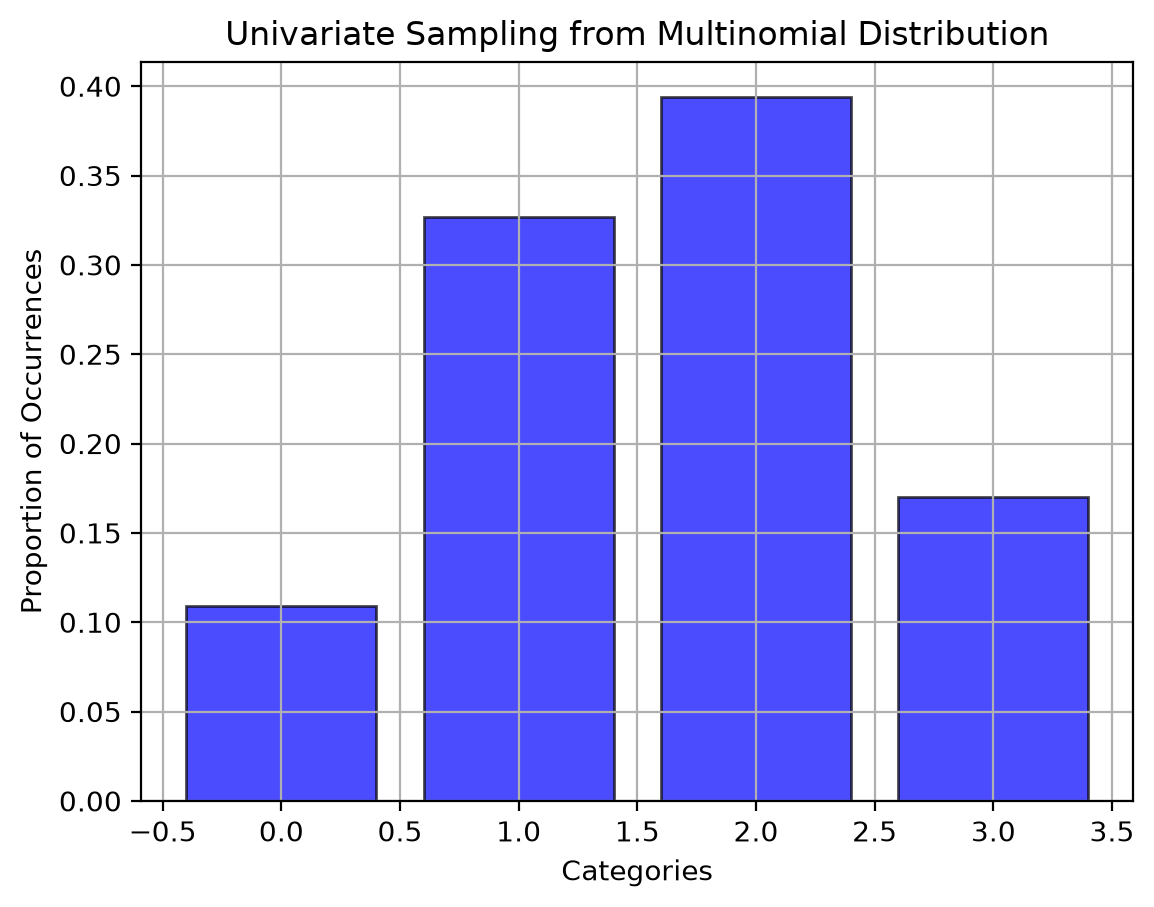

In [8]:
plot_density(mn_samples)

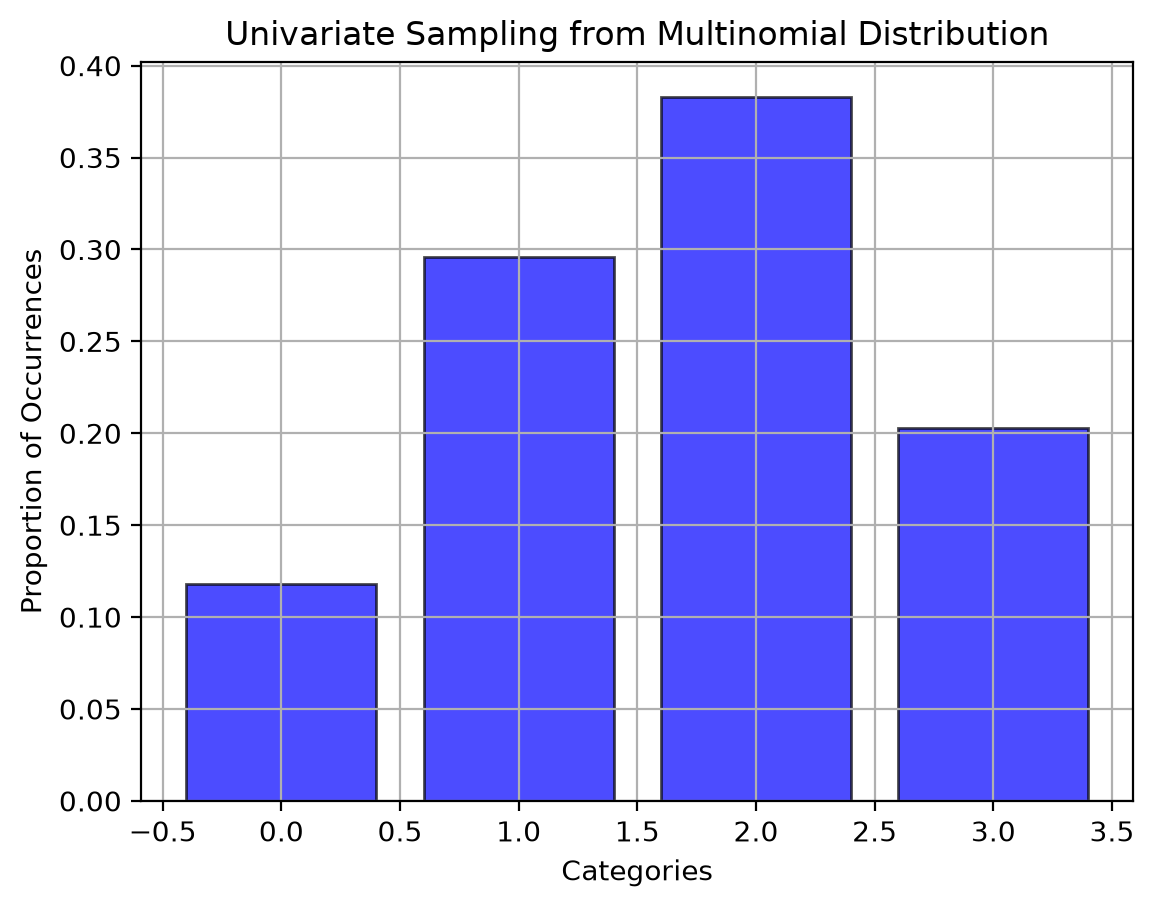

In [9]:
np_samples = np.random.multinomial(1, multinomial_p, size=1000)
plot_density(np_samples)

In [10]:
np_samples[0]

array([0, 0, 0, 1], dtype=int32)

## 2. Rejection Sampling

Rejection sampling is used to generate random samples from a target distribution by using a simpler proposal distribution. The key steps are:

* Choose a proposal distribution: Select a distribution that's easy to sample from and covers the target distribution.
* Generate samples: Randomly draw samples from the proposal distribution.
* Accept or reject: For each sample, compute a ratio between the target and proposal distributions. Accept the sample with a probability proportional to this ratio. Otherwise, reject the sample and try again.

In this example, the unnormalized target distribution is $\tilde{P}(Z) = \exp(-\frac{Z^2}{2}) * (\sin(6 + Z)^2 + 3 * \cos(Z)^2 * \sin(4Z)^2 + 1)$. We compare uniform distribution with Gaussian distribution as the proposal distribution.

In [11]:
def p(z):
    return exp(-z**2/2) * (sin(6 + z)**2 + 3 * cos(z)**2 * sin(4 * z)**2 + 1)

Assume the range of Z is [-3, 3]

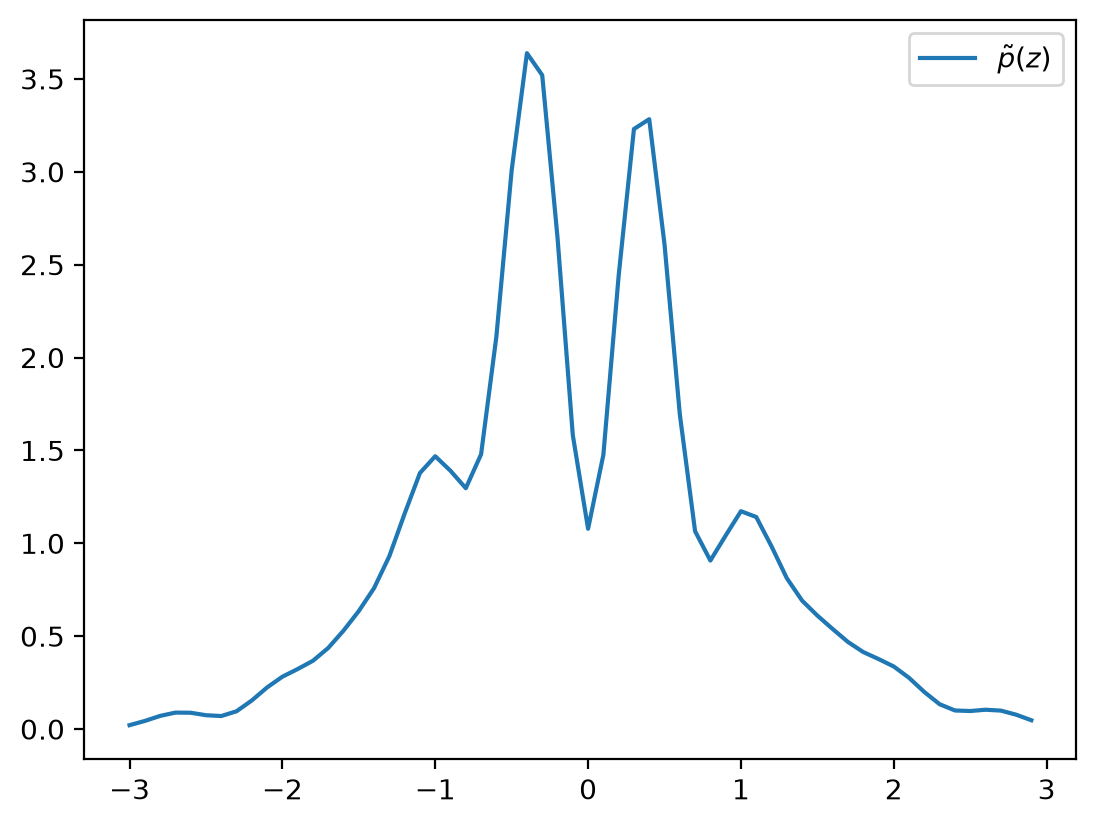

In [12]:
z = np.arange(-3, 3, 0.1)
fig, ax = plt.subplots()
ax.plot(z, p(z), label=r"$\tilde{p}(z)$")
plt.legend()
plt.show()

Define two proposal distributions:
* Z is uniformly distributed over [-3, 3]
* Z follows the Gaussian distribution $\mathcal{N}(0,1)$

In [13]:
def q(z, gaussian=False):
    if gaussian:
        return norm.pdf(z, loc =0, scale = 1)
    return uniform.pdf(z, loc=-3, scale=6)

### 2.1 Start with a uniform distribution over $[a, b]$

$q(Z) =
\begin{cases}
\frac{1}{b - a}, & \text{for } a \leq x \leq b \\
0, & \text{otherwise}
\end{cases}$

Goal: introduce a constant k so that $kq(Z) \geq \tilde{p}(Z)$

To find $k$, we pick the largest $\tilde{p}(Z)$ in $[a, b]$ so that $k q(Z) = \max_{z \in [-3, 3]} \tilde{p}(z) \geq \tilde{p}(Z)$.
As the probabilities are the same over $[-3, 3]$, for any $z_0 \in [-3, 3]$ we know that $\frac{\max \tilde{p}(Z)}{q(z_0)} q(z) = \max \tilde{p}(Z)$ for all z in $[-3, 3]$. For simplicity, we choose $z_0 = 0$. 

In [14]:
# Let z0 = 0
q(0)

np.float64(0.16666666666666666)

We plot both the comparison function $kq(Z)$ and $\tilde{p}(Z)$.

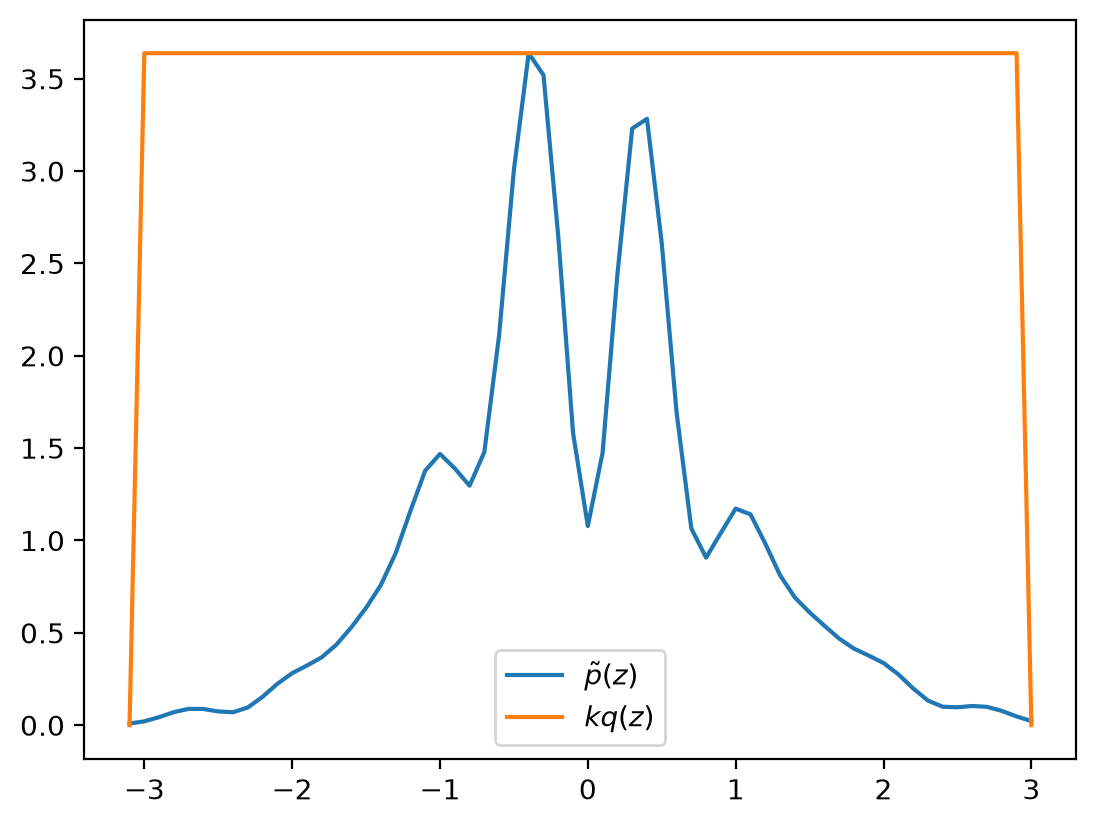

In [15]:
z = np.arange(-3.1, 3.1, 0.1)

# compute k = max_z p~(z) / q(z); q is constant on [-3, 3], so q(0) will do
k = max(p(z)/q(0))
fig, ax = plt.subplots()
ax.plot(z, p(z), label=r"$\tilde{p}(z)$")
ax.plot(z, k*q(z), label=r"$kq(z)$")
plt.legend()
plt.show()

In [16]:
k

np.float64(21.830156386293226)

Three steps to sample an instance

1. Generate a number $z_0$ from the uniform distribution $q(Z)$.
2. Generate a number $u_0$ uniformly from $[0, kq(z_0)]$.
3. If $u_0 < \tilde{p}(z_0)$, accept $z_0$; otherwise reject it.

In [17]:
def sample(size):
    xs = np.random.uniform(-3, 3, size=size)
    comparison_func =  k * q(xs)
    cs = np.random.uniform(0, 1, size=size) * comparison_func
    mask = p(xs) > cs
    return xs[mask]   

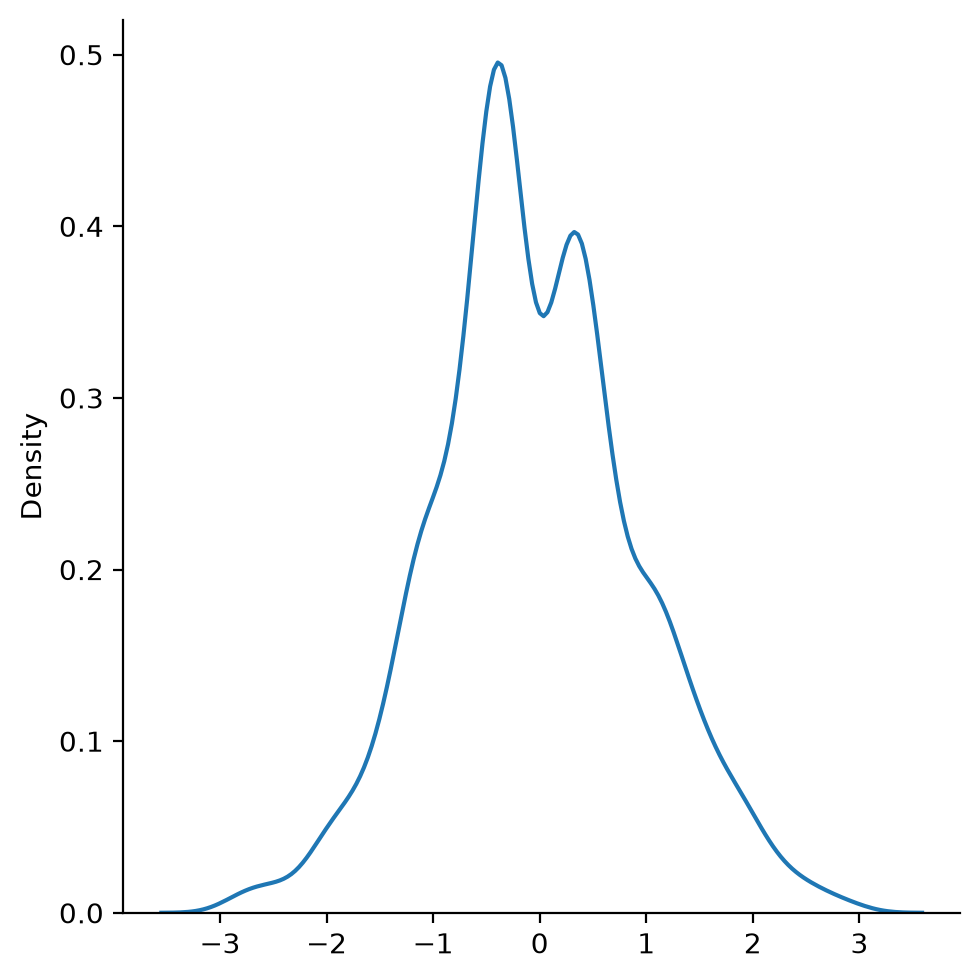

In [18]:
samples_uniform = sample(10000)
sns.displot(samples_uniform, kind='kde')
plt.show()

In [19]:
print('The mean value is {0}'.format(np.mean(samples_uniform)))

The mean value is -0.03622120650209911


In [20]:
print("Acceptance rate using a uniform distribution : %.2f" % float(len(samples_uniform)/10000))

Acceptance rate using a uniform distribution : 0.26


### 2.2 Change the proposal distribution to $q(Z) = \mathcal{N}(0,1)$

Change $k = \max_z \frac{\tilde{p}(Z)}{q(Z)}$ so that $kq(Z) \geq \tilde{p}(Z)$

In [21]:
k_normal = np.max(p(z) / q(z, True))
k_normal

np.float64(9.879593807738045)

Plot both the comparison function and the unnormalized target distribution.

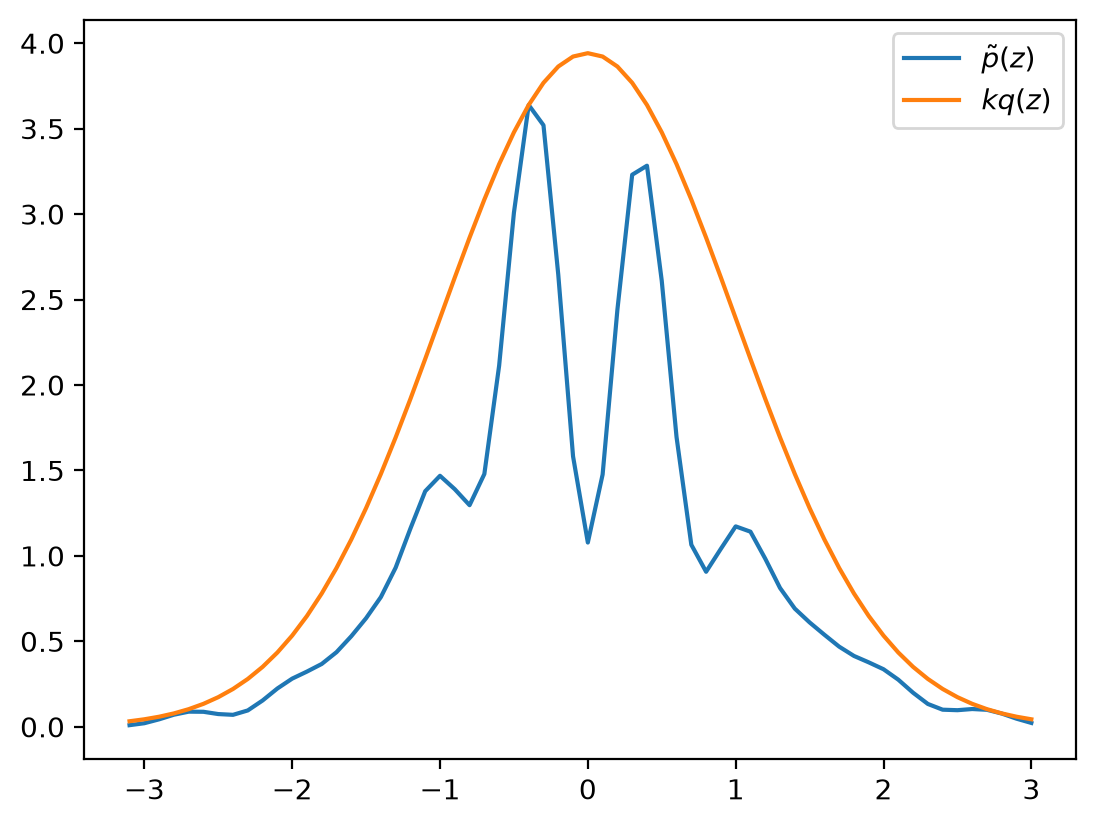

In [22]:
fig, ax = plt.subplots()
ax.plot(z, p(z), label=r"$\tilde{p}(z)$")
ax.plot(z, k_normal*q(z, True), label=r"$kq(z)$")
plt.legend()
plt.show()

### Activity I: Apply Rejection Sampling using Gaussian as the Proposal Distribution

* Compute the expected value using the samples.
* Compute the acceptance rate.


Three steps to sample an instance

1. Generate a number $z_0$ from the Gaussian distribution $\mathcal{N}(Z|0,1)$.
2. Generate a number $u_0$ uniformly from $[0, kq(z_0)]$.
3. If $u_0 < \tilde{p}(z_0)$, accept $z_0$; otherwise reject it.

#### Complete the following sampling function using Gaussian as the proposal distribution.

In [23]:
def sample_normal(size):
    xs = np.random.randn(size)
    k_gaussian = k_normal * q(xs, True)
    cs = np.random.uniform(0, 1, size=size) * k_gaussian
    mask = p(xs) > cs
    return xs[mask]   

#### Sample 10000 instances using your method and plot its distribution.

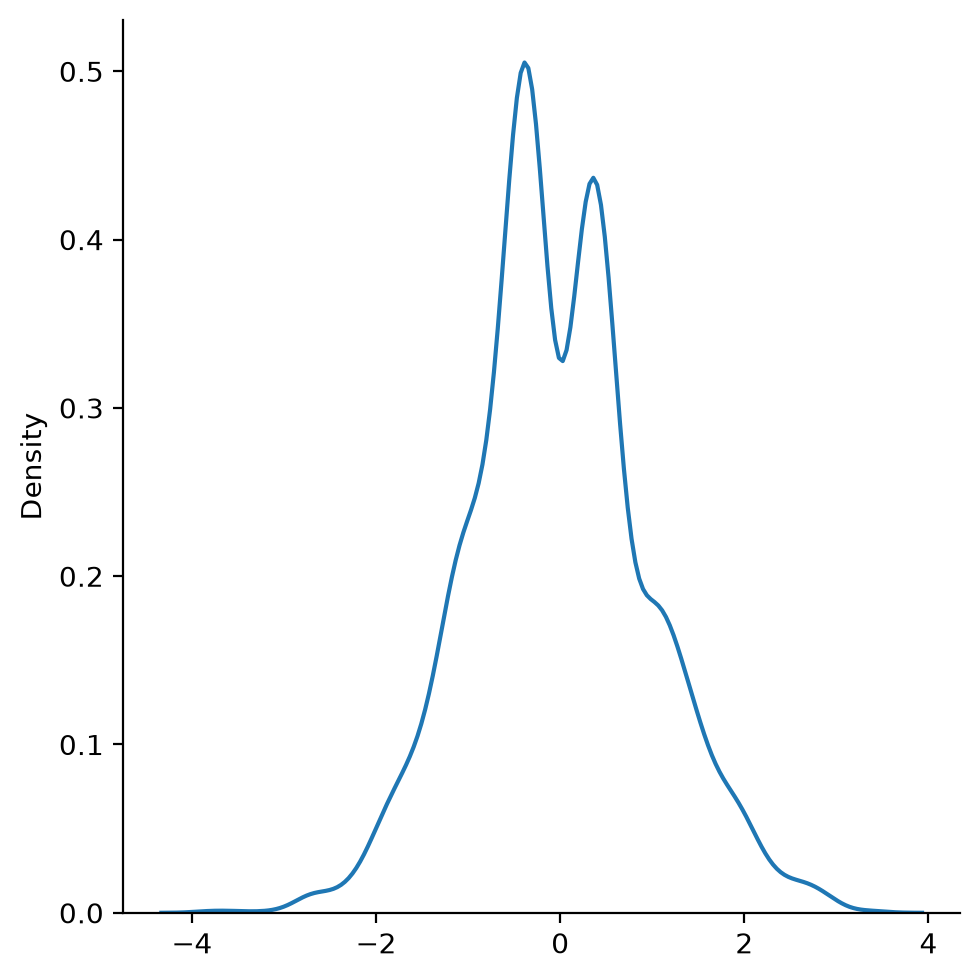

In [24]:
samples_norm = sample_normal(10000)
sns.displot(samples_norm, kind='kde')
plt.show()

#### Compute the acceptance rate for your samples.

In [25]:
print("Acceptance rate using a uniform distribution : %.2f" % float(len(samples_uniform)/10000))
print("Acceptance rate using a Gaussian distribution : %.2f" % float(len(samples_norm)/10000))

Acceptance rate using a uniform distribution : 0.26
Acceptance rate using a Gaussian distribution : 0.59


#### Compute the expectation.

In [26]:
print('The mean value using a uniform distribution is {0}'.format(np.mean(samples_uniform)))
print('The mean value using a Gaussian distribution is {0}'.format(np.mean(samples_norm)))

The mean value using a uniform distribution is -0.03622120650209911
The mean value using a Gaussian distribution is -0.02091052509462699


## 3. Comparison between Forward Sampling, Rejection Sampling and Gibbs Sampling

### 3.1 Compute $E[Cancer]$ and $E[Dyspnoea]$, the expected values of Cancer and Dyspnoea (with True = 1, False = 0).

#### Demo

In [27]:
def visualize(bayesianNet, file_name = 'cancer'):
    viz = bayesianNet.to_graphviz()
    viz.draw('%s.png' % file_name, prog='dot')
    return Image('%s.png' % file_name)

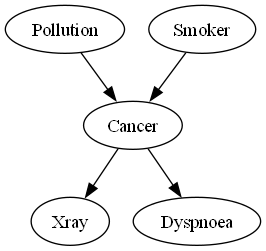

In [28]:
# Load the model
cancer_model = load_example_model('cancer')
visualize(cancer_model)

In [29]:
cancer_sampler = BayesianModelSampling(cancer_model)

#### Forward Sampling

In [30]:
samples_forward = cancer_sampler.forward_sample(size=1000, show_progress=False)

In [31]:
samples_forward.head()

,Pollution,Smoker,Cancer,Xray,Dyspnoea
0,low,True,False,negative,True
1,low,False,False,negative,False
2,low,False,False,negative,False
3,low,False,False,negative,True
4,low,False,False,negative,True


In [32]:
def cal_expectation(samples, variable):
    # Treat the state 'True' as 1 and every other state as 0, so the mean is the expected value
    return (samples[variable] == 'True').mean()

In [33]:
print('E[Cancer] = {0},  E[Dyspnoea] = {1}'.format(cal_expectation(samples_forward, 'Cancer'),cal_expectation(samples_forward, 'Dyspnoea')))

E[Cancer] = 0.011,  E[Dyspnoea] = 0.314


#### Rejection Sampling

In [34]:
samples_rej = cancer_sampler.rejection_sample(size=1000, show_progress=False)

  0%|          | 0/5 [00:00<?, ?it/s]

In [35]:
samples_rej.head()

,Pollution,Smoker,Cancer,Xray,Dyspnoea
0,low,False,False,negative,False
1,low,False,False,positive,True
2,low,False,False,negative,False
3,low,True,False,negative,False
4,low,True,False,negative,False


In [36]:
print('E[Cancer] = {0},  E[Dyspnoea] = {1}'.format(cal_expectation(samples_rej, 'Cancer'),cal_expectation(samples_rej, 'Dyspnoea')))

E[Cancer] = 0.013,  E[Dyspnoea] = 0.289


### 3.2 Introduce Evidence

Now we compute $E[Cancer | Xray = 'positive']$

### Activity II: Apply Rejection Sampling and Forward Sampling to compute $E[Cancer | Xray = 'positive']$. 

Read the document of [BayesianModelSampling](https://pgmpy.org/api/generated/inference/pgmpy.sampling.BayesianModelSampling.html) for further information. Apply each of the methods to sample 1000 particles.

In [37]:
samples_rej_xray = cancer_sampler.rejection_sample(size=1000, evidence=[State(var='Xray', state='positive')], show_progress=False)

In [38]:
print('E[Cancer] = {0}'.format(cal_expectation(samples_rej_xray, 'Cancer')))

E[Cancer] = 0.045


As forward sampling does not directly cope with evidence, we can keep only the sampled instances that are consistent with the evidence. Use boolean indexing of DataFrame to select the corresponding rows. 

In [39]:
filtered_samples = samples_forward[samples_forward['Xray'] == 'positive']

In [40]:
filtered_samples.shape[0]

210

In [41]:
print('E[Cancer] = {0}'.format(cal_expectation(filtered_samples, 'Cancer')))

E[Cancer] = 0.04285714285714286


### 3.3 Answer Probability Queries

Compute $P(Cancer | Xray = 'positive')$

In [42]:
infer = ApproxInference(cancer_model)

In [43]:
print(infer.query(variables=['Cancer'], evidence={'Xray':'positive'}, n_samples=1000, show_progress=False))

# For comparison, the exact answer from variable elimination
print(VariableElimination(cancer_model).query(variables=['Cancer'], evidence={'Xray':'positive'}, show_progress=False))

+---------------+---------------+
| Cancer        |   phi(Cancer) |
+===============+===============+
| Cancer(False) |        0.9440 |
+---------------+---------------+
| Cancer(True)  |        0.0560 |
+---------------+---------------+
+---------------+---------------+
| Cancer        |   phi(Cancer) |
+===============+===============+
| Cancer(True)  |        0.0503 |
+---------------+---------------+
| Cancer(False) |        0.9497 |
+---------------+---------------+


### 3.4 Gibbs Sampling

[pyAgrum](https://pyagrum.readthedocs.io/en/latest/notebooks/44-Inference_ApproximateInference.html) is a Python library designed for building, manipulating, and performing inference on probabilistic graphical models such as Bayesian Networks and Markov Networks. We demonstrate Gibbs sampling with pyAgrum because its Gibbs sampler supports evidence (pgmpy's `GibbsSampling.sample()` has no evidence argument).

In [44]:
#! pip install pyagrum

In [45]:
# pyAgrum >= 2.0 is imported as the lowercase package `pyagrum` (the old `pyAgrum` name no longer exists)
import pyagrum as gum
import pyagrum.lib.notebook as gnb

In [46]:
# Save the cancer model to a file
bif_writer = BIFWriter(cancer_model)
bif_writer.write('cancer.bif')   # write_bif() is deprecated in pgmpy 1.1

# Load the cancer model from the file
bn_cancer = gum.loadBN('cancer.bif')

Create a GibbsSampling object.

In [47]:
gibbs_sampler = gum.GibbsSampling(bn_cancer)

Visualize Gibbs sampling using [showInference()](https://pyagrum.readthedocs.io/en/latest/lib.notebook.html#pyAgrum.lib.notebook.showInference).

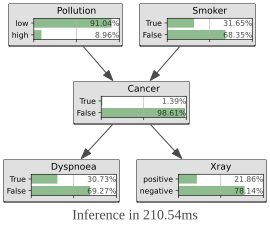

In [48]:
# Without evidence
gibbs_sampler.setEpsilon(1e-2)
gnb.showInference(bn_cancer,engine=gibbs_sampler,size="5")

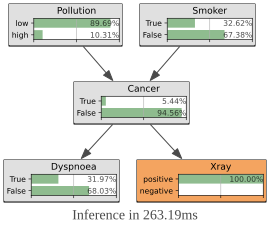

In [49]:
# With evidence
gnb.showInference(bn_cancer,evs = {'Xray':'positive'},engine=gibbs_sampler,size="5")

Apply approximate inference without visualization.

In [50]:
# Set the evidence first, then run the inference, then read the posterior
gibbs_sampler.setEvidence({'Xray':'positive'})
gibbs_sampler.makeInference()
gibbs_sampler.posterior('Cancer')

(pyagrum.Tensor@0000017C02C5F700) 
  Cancer           │
True     │False    │
─────────│─────────│
 0.0540  │ 0.9460  │

### Demo: Comparison of Inference Methods

Answer the probability query $P(ThisCarCost | GoodStudent = 'True')$.

In [51]:
insurance_model = load_example_model('insurance')

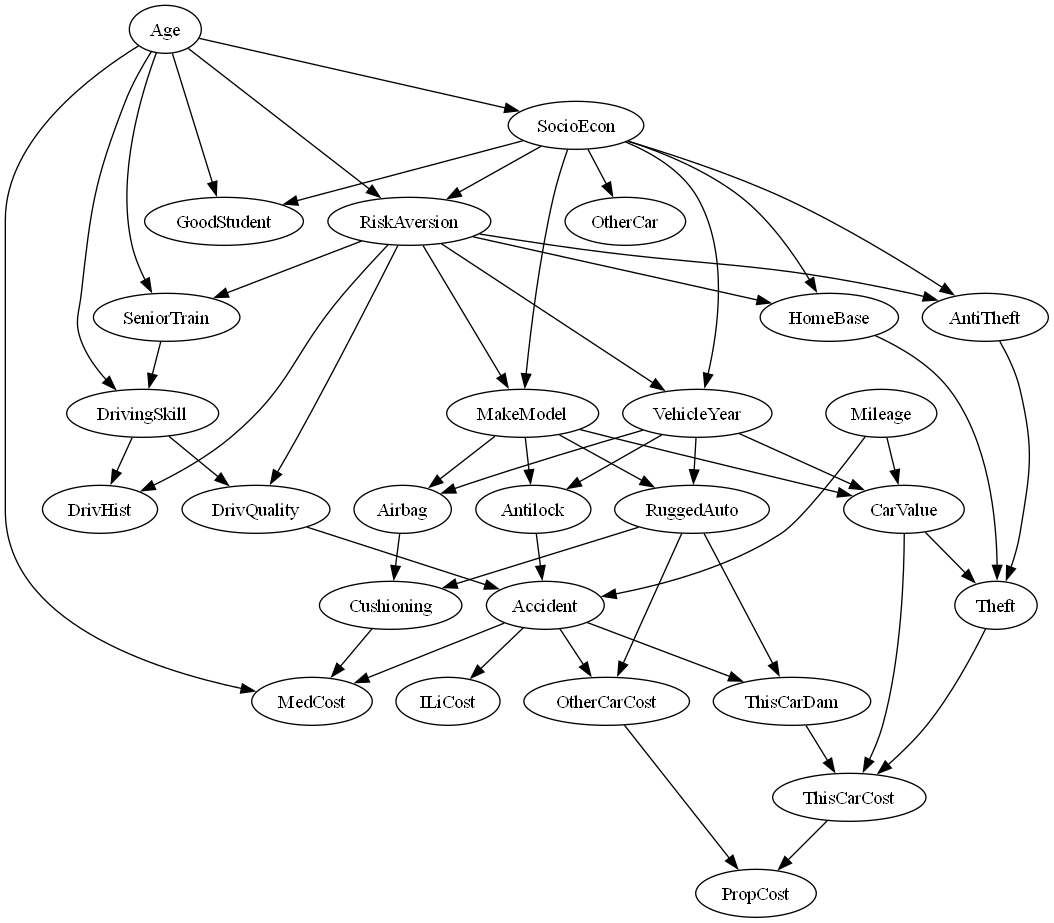

In [52]:
visualize(insurance_model, 'INSURANCE')

In [53]:
print(insurance_model.get_cpds('GoodStudent'))

+--------------------+------------------+-----+--------------------+--------------------+
| SocioEcon          | SocioEcon(Prole) | ... | SocioEcon(Wealthy) | SocioEcon(Wealthy) |
+--------------------+------------------+-----+--------------------+--------------------+
| Age                | Age(Adolescent)  | ... | Age(Adult)         | Age(Senior)        |
+--------------------+------------------+-----+--------------------+--------------------+
| GoodStudent(True)  | 0.1              | ... | 0.0                | 0.0                |
+--------------------+------------------+-----+--------------------+--------------------+
| GoodStudent(False) | 0.9              | ... | 1.0                | 1.0                |
+--------------------+------------------+-----+--------------------+--------------------+


In [54]:
def evaluate_inf(inference):
    start_time = time.time()
    result = inference.query(variables=['ThisCarCost'], evidence={'GoodStudent':'True'}, show_progress=False)
    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"Running time: {elapsed_time:.6f} seconds")
    print(result)

#### Apply Sum-Product algorithm

In [55]:
insurance_ve = VariableElimination(insurance_model)

In [56]:
evaluate_inf(insurance_ve)

Running time: 0.019093 seconds
+--------------------------+--------------------+
| ThisCarCost              |   phi(ThisCarCost) |
+==========================+====================+
| ThisCarCost(Thousand)    |             0.7527 |
+--------------------------+--------------------+
| ThisCarCost(TenThou)     |             0.1379 |
+--------------------------+--------------------+
| ThisCarCost(HundredThou) |             0.1083 |
+--------------------------+--------------------+
| ThisCarCost(Million)     |             0.0010 |
+--------------------------+--------------------+


#### Apply Rejection Sampling based Approximate Inference

In [57]:
rej_insurance = ApproxInference(insurance_model)
evaluate_inf(rej_insurance)

Running time: 14.956315 seconds
+--------------------------+--------------------+
| ThisCarCost              |   phi(ThisCarCost) |
+==========================+====================+
| ThisCarCost(Thousand)    |             0.7553 |
+--------------------------+--------------------+
| ThisCarCost(TenThou)     |             0.1377 |
+--------------------------+--------------------+
| ThisCarCost(HundredThou) |             0.1058 |
+--------------------------+--------------------+
| ThisCarCost(Million)     |             0.0012 |
+--------------------------+--------------------+


#### Apply Gibbs Sampling

Gibbs sampling needs many sweeps to approximate the posterior well. pyAgrum's default stopping rule (`epsilon` = 0.2, checked every 100 sweeps after a burn-in of 300) stops almost immediately, so we compare the default run with a run of 100,000 sweeps. Each sweep changes one variable at a time given its Markov blanket, so consecutive samples are strongly correlated and the chain moves slowly through a network like `insurance`, where several variables are nearly determined by their parents.

In [58]:
# Save the insurance model to a file
ins_writer = BIFWriter(insurance_model)
ins_writer.write('insurance.bif')

# Load the insurance model from the file
bn_insurance = gum.loadBN('insurance.bif')

In [59]:
def evaluate_gibbs(model, n_sweeps=None, burn_in=None):
    start_time = time.time()
    gibbs = gum.GibbsSampling(model)
    gibbs.addTarget('ThisCarCost')
    gibbs.setEvidence({'GoodStudent':'True'})
    if n_sweeps is not None:
        # Run a fixed number of Gibbs sweeps instead of pyAgrum's convergence test
        gibbs.setEpsilon(0)
        gibbs.setMinEpsilonRate(0)
        gibbs.setMaxIter(n_sweeps)
    if burn_in is not None:
        gibbs.setBurnIn(burn_in)
    gibbs.makeInference()       # run after the target, evidence and stopping criteria are set
    result = gibbs.posterior('ThisCarCost')
    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"Running time: {elapsed_time:.6f} seconds, {gibbs.nbrIterations()} sweeps")
    return result

In [60]:
# With pyAgrum's default stopping criteria (epsilon = 0.2, burn-in = 300 sweeps), the sampler
# stops right after the burn-in and the estimate is far from the exact answer above.
evaluate_gibbs(bn_insurance)

Running time: 0.253663 seconds, 300 sweeps


(pyagrum.Tensor@0000017C271FB8E0) 
  ThisCarCost                          │
Thousand │TenThou  │HundredTh│Million  │
─────────│─────────│─────────│─────────│
 0.8833  │ 0.1167  │ 0.0000  │ 0.0000  │

In [61]:
# 100,000 sweeps after a burn-in of 5,000: close to the exact answer, but no longer cheap
evaluate_gibbs(bn_insurance, n_sweeps=100000, burn_in=5000)

Running time: 31.729013 seconds, 100000 sweeps


(pyagrum.Tensor@0000017C271FBBA0) 
  ThisCarCost                          │
Thousand │TenThou  │HundredTh│Million  │
─────────│─────────│─────────│─────────│
 0.7644  │ 0.1196  │ 0.1159  │ 0.0000  │